<a href="https://colab.research.google.com/github/13rustam/Zhanakorgan_Agriculture/blob/main/Water_Crop_Use_Kaz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [78]:
!pip install -q --upgrade earthengine-api geemap xee matplotlib

import ee
import geemap
import matplotlib.pyplot as plt
import shapely.geometry
import xarray as xr
from xee import helpers



In [79]:
# ----------------------------------------------------------------------
# Settings
# ----------------------------------------------------------------------
PROJECT = 'fifth-trainer-489105-c1'
RAYON_ASSET = f'projects/{PROJECT}/assets/Kazakhstan_Rayon_2023'
FIELDS_ASSET = f'projects/{PROJECT}/assets/Deliniated_Zhanakorgan_2023'

YEAR = 2025
MONTHS = range(2, 12)          # Feb-Nov: the months actually covered by data
MAX_CLOUD_PCT = 60             # scene-level pre-filter (cheap, saves compute)
PLOT_SCALE = 100               # metres; coarse grid for the facet plot (see notes)
NDVI_VIS = {'min': 0, 'max': 0.8,
            'palette': ['#a50026', '#f46d43', '#fee08b', '#a6d96a', '#1a9850', '#006837']}


In [80]:
# ----------------------------------------------------------------------
# 1. Authenticate / initialise
# ----------------------------------------------------------------------
# Note: the argument is `opt_url`, not `url`. The high-volume endpoint is meant
# for xee/bulk requests; if interactive map tiles feel slow, initialise with the
# default endpoint and only switch to high-volume before opening the xarray data.
try:
    ee.Initialize(project=PROJECT,
                  opt_url='https://earthengine-highvolume.googleapis.com')
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT,
                  opt_url='https://earthengine-highvolume.googleapis.com')

In [81]:
# ----------------------------------------------------------------------
# 2. Study area (whole district) and fields (overlay only)
# ----------------------------------------------------------------------
rayon = ee.FeatureCollection(RAYON_ASSET)
district = rayon.filter(ee.Filter.eq('ADM2_EN', 'Zhanakorgan District'))
roi = district.geometry()

fields = ee.FeatureCollection(FIELDS_ASSET)   # NOT used for NDVI, display only

print('District features found:', district.size().getInfo())   # should be 1

District features found: 1


In [82]:
# ----------------------------------------------------------------------
# 3. Sentinel-2 + cloud mask + NDVI
# ----------------------------------------------------------------------
def mask_s2(image):
    """Mask no-data, saturated, cloud shadow, clouds, cirrus and snow (SCL)."""
    scl = image.select('SCL')
    bad = scl.eq(0).Or(scl.eq(1)).Or(scl.eq(3)).Or(scl.gte(8).And(scl.lte(11)))
    return image.updateMask(bad.Not())


def add_ndvi(image):
    return image.addBands(image.normalizedDifference(['B8', 'B4']).rename('NDVI'))


s2_ndvi = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(roi)
    .filterDate(f'{YEAR}-01-01', f'{YEAR + 1}-01-01')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', MAX_CLOUD_PCT))
    .map(mask_s2)
    .map(add_ndvi)
    .select('NDVI')
)

In [83]:
# ----------------------------------------------------------------------
# 4. Monthly max-NDVI composites (no reproject: keeps it lazy and fast)
# ----------------------------------------------------------------------
def monthly_composite(m):
    start = ee.Date.fromYMD(YEAR, m, 1)
    img = (
        s2_ndvi.filterDate(start, start.advance(1, 'month'))
        .max()
        .rename('NDVI')
        .clip(roi)
    )
    # system:time_start is what xee uses to build the time dimension
    return img.set({'month': m, 'system:time_start': start.millis()})


monthly = ee.ImageCollection.fromImages([monthly_composite(m) for m in MONTHS])

Generating monthly NDVI facet plot...


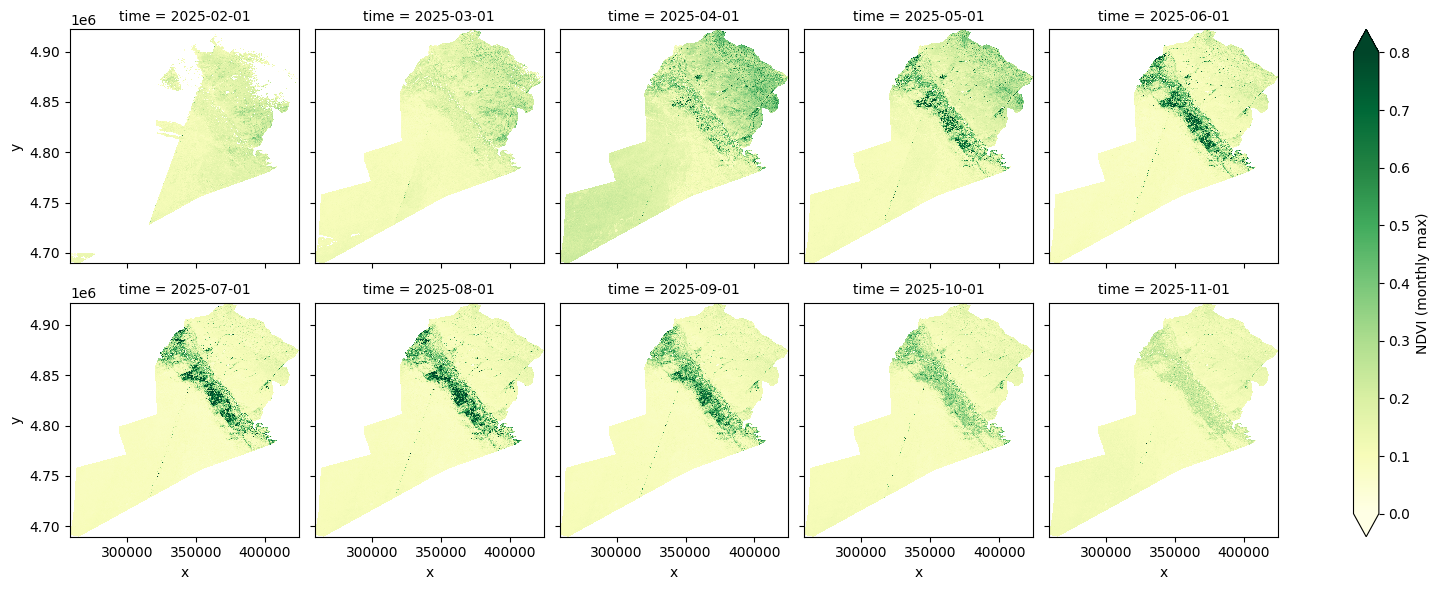

In [84]:
# ----------------------------------------------------------------------
# 5. Facet plot via xarray (coarse grid; native 10 m would be ~10x10 times larger)
# ----------------------------------------------------------------------
shapely_geom = shapely.geometry.shape(roi.simplify(100).getInfo())

grid = helpers.fit_geometry(
    geometry=shapely_geom,
    geometry_crs='EPSG:4326',
    grid_crs='EPSG:32642',
    grid_scale=(PLOT_SCALE, -PLOT_SCALE),
)
ds = xr.open_dataset(monthly, engine='ee', **grid)

print('Generating monthly NDVI facet plot...')
ds['NDVI'].plot(
    col='time', col_wrap=5, cmap='YlGn', vmin=0, vmax=0.8,
    cbar_kwargs={'label': 'NDVI (monthly max)'},
)
plt.show()

In [85]:
# ----------------------------------------------------------------------
# 6. Interactive map: district NDVI at full 10 m + field boundaries on top
# ----------------------------------------------------------------------
Map = geemap.Map()
Map.centerObject(district, 9)

Map.addLayer(monthly.mean().clip(roi), NDVI_VIS, f'{YEAR} mean of monthly max NDVI')
Map.addLayer(monthly.max().clip(roi), NDVI_VIS, f'{YEAR} peak NDVI', False)

# One toggleable layer per month
for m in MONTHS:
    img = monthly.filter(ee.Filter.eq('month', m)).first()
    Map.addLayer(img, NDVI_VIS, f'NDVI {YEAR}-{m:02d}', False)

# Overlays (added last so they sit on top)
Map.addLayer(fields.style(color='black', fillColor='00000000', width=1),
             {}, 'Delineated fields')
Map.addLayer(district.style(color='red', fillColor='00000000', width=2),
             {}, 'Zhanakorgan District boundary')

Map.add_colorbar(NDVI_VIS, label='NDVI', layer_name=f'{YEAR} mean of monthly max NDVI')
Map

Map(center=[43.43741817070838, 67.09229390138452], controls=(WidgetControl(options=['position', 'transparent_b…